# FishSizeEstimate — Final Measurement Investigation & Evidence Notebook

**Purpose:** finish the missing scientific work after the successful V8 visual-encoder pretraining. This notebook **does not spend another 30–40 minutes retraining**. It reads the actual uploaded dataset, audits the existing tracking annotations, extracts synchronized stereo candidates, uses conservative image segmentation proposals, inspects stereo calibration, and attempts **evidence-gated physical length measurement**.

**Critical boundary:** There is no guarantee of valid centimetre estimates. Numeric cm output requires a verified physical baseline, matching calibrated/rectified frames, *correct left/right nose and tail correspondences*, and verified fish identities. It will never manufacture these prerequisites. A 3D estimate without them is a geometrical hypothesis, not a validated fish-length predictor.

### Inputs
- `/kaggle/input/datasets/wafabila/fishsizeestimate-dataset` (11 recovered ROS1 bags)
- V8 checkpoint **optional** under an attached Kaggle notebook-output dataset; this notebook does not need it to conduct the geometry audit
- Optional verified annotation CSV and a verified calibration mapping CSV, **only if independently confirmed**

### Outputs
Metadata audits, annotation schema evidence, actual stereo pairs, conservative mask/end-point proposals, review sheets, calibration report, optional verified 3D measurements and eligible grouped evaluation, final machine-readable status, downloadable ZIP. No third-party `.pt` is unpickled by default.

## 0 — Setup and guards

In [1]:
import sys, subprocess, importlib.util, os, json, re, math, hashlib, csv, time, zipfile
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path('/kaggle/input/datasets/wafabila/fishsizeestimate-dataset')
OUT=Path('/kaggle/working/fishsizeestimate_final_measurement')
OUT.mkdir(parents=True,exist_ok=True)
assert ROOT.exists(),f'Missing Kaggle dataset: {ROOT}'
SEED=42; np.random.seed(SEED)
MAX_STEREO_PAIRS_PER_BAG=6
MAX_PAIR_DELTA_MS=25.0
PREVIEW_MAX_EDGE=960
# Must be independently verified from hardware documentation; do NOT fill from an unexplained candidate value.
VERIFIED_BASELINE_METERS=None
# Must correspond to the particular bag acquisition/calibration session.
VERIFIED_BAG_CALIBRATION_MAP=Path('/kaggle/input/fishsizeestimate-verified/verified_bag_calibration_map.csv')
VERIFIED_ENDPOINTS=Path('/kaggle/input/fishsizeestimate-verified/fish_endpoint_annotations.csv')
# This is a trusted-data decision, not an image-model quality score.
ALLOW_UNTRUSTED_MODEL_PICKLE=False
if importlib.util.find_spec('rosbags') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','rosbags>=0.10,<0.12'])
from rosbags.highlevel import AnyReader
try:
    import yaml
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','pyyaml'])
    import yaml
print('Environment:',sys.version.split()[0],cv2.__version__)
print('Dataset:',ROOT,'Output:',OUT)

Environment: 3.13.16 4.14.0
Dataset: /kaggle/input/datasets/wafabila/fishsizeestimate-dataset Output: /kaggle/working/fishsizeestimate_final_measurement


## 1 — File and specimen ground-truth inventory
Full source file names and lengths are preserved. A recording is not the same as a unique fish label.

In [2]:
files=sorted(p for p in ROOT.rglob('*') if p.is_file())
bags=sorted([p for p in files if p.suffix.lower()=='.bag'])
manifest_file=next((p for p in files if p.name=='source_manifest.json'),None)
manifest=json.loads(manifest_file.read_text(encoding='utf-8-sig')) if manifest_file else {}
manifest_lookup={str(x.get('upload_name')):str(x.get('original_path','')) for x in manifest.get('files',[]) if isinstance(x,dict)}
def original_path(p):return manifest_lookup.get(p.name,p.name)
def ds_of(p):
    q=original_path(p).replace('\\','/').lower()
    return 'B' if '/dataset_b/' in q else ('A' if '/dataset_a/' in q else 'UNKNOWN')
inv=pd.DataFrame([{'bag':p.name,'dataset':ds_of(p),'source_path':original_path(p),'bytes':p.stat().st_size} for p in bags])
inv.to_csv(OUT/'source_inventory.csv',index=False)
gtfile=next((p for p in files if p.name.endswith('fish_gt_measures.csv')),None)
assert gtfile is not None, 'Ground-truth file missing'
gt=pd.read_csv(gtfile,dtype=str,encoding='utf-8-sig')
gt['Total_Length_cm']=pd.to_numeric(gt['Total_Length_cm'].str.replace(',','.',regex=False),errors='raise')
gt.to_csv(OUT/'physical_ground_truth_source.csv',index=False)
print('Recovered ROS bags:',len(bags),'GT identities:',len(gt),'recovery:',manifest.get('status'))
display(inv,gt[['Dataset','Identifier','Total_Length_cm']])

Recovered ROS bags: 11 GT identities: 9 recovery: partial recovery


,bag,dataset,source_path,bytes
0,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,2303643783
1,14f5cd7cd8f7_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,1507701951
2,4efb770e7d98_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,2302137135
3,639d8b0d6198_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,2253331144
4,6409f636e6f9_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,2661896180
5,697d94299f75_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,3193012706
6,6b771e0b4b26_r_stereo_camera_images_2025-08-21...,B,bagfiles/Dataset_B/multiple_fish/retalls_compr...,2681258607
7,776e174bb797_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,2130028393
8,83b92bcd3ce0_r_stereo_camera_images_2025-08-21...,B,bagfiles/Dataset_B/multiple_fish/retalls_compr...,918505806
9,943687d73044_stereo_camera_images_2024-11-12-1...,A,bagfiles/Dataset_A/2024_11_12/2024_11_12/singl...,2228761641


,Dataset,Identifier,Total_Length_cm
0,Dataset A,Fish 0,31.5
1,Dataset A,Fish 1,28.9
2,Dataset A,Fish 2,21.6
3,Dataset A,Fish 3,33.5
4,Dataset A,Fish 4,33.5
5,Dataset A,Fish 5,30.0
6,Dataset B,Red Tag,29.1
7,Dataset B,Black Tag,26.6
8,Dataset B,Unmarked,32.3


## 2 — Inspect the real annotation JSON before assuming its labels
This prints nested key paths and safely truncated examples. It does **not** treat arbitrary tracking IDs as fish identities or fish lengths.

In [3]:
json_candidates=[p for p in files if p.suffix.lower()=='.json' and ('track' in p.name.lower() or 'annot' in p.name.lower())]
annotations_inventory=[]
def walk_schema(obj,path='$',depth=0,limit=5,counts=None):
    if counts is None:counts=Counter()
    if depth>limit:return counts
    counts[f'{path} :: {type(obj).__name__}']+=1
    if isinstance(obj,dict):
        for k,v in list(obj.items())[:35]:walk_schema(v,path+'.'+str(k),depth+1,limit,counts)
    elif isinstance(obj,list) and obj:
        walk_schema(obj[0],path+'[0]',depth+1,limit,counts)
    return counts
annotation_obj={}
for p in json_candidates:
    try:
        data=json.loads(p.read_text(encoding='utf-8-sig'))
        annotation_obj[p.name]=data
        schema=walk_schema(data)
        (OUT/(p.stem+'_schema.txt')).write_text('\n'.join(f'{v:5d} {k}' for k,v in schema.most_common(400)),encoding='utf-8')
        annotations_inventory.append({'name':p.name,'source':original_path(p),'bytes':p.stat().st_size,'root_type':type(data).__name__,'top_keys':str(list(data.keys())[:25]) if isinstance(data,dict) else None,'schema_lines':len(schema)})
    except Exception as e:annotations_inventory.append({'name':p.name,'error':str(e)[:300]})
ann_inv=pd.DataFrame(annotations_inventory)
ann_inv.to_csv(OUT/'tracking_annotation_inventory.csv',index=False)
display(ann_inv)
print('Review *_schema.txt to determine whether this file stores boxes, masks, identities, endpoints, and timestamps.')

,name,source,bytes,root_type,top_keys,schema_lines
0,22979fe6cf08_model_tracking_annotations.json,dataset_to_zenodo/gt_annotations_and_samples/m...,9873,dict,"['metadata', 'single_fish_tracks', 'multiple_f...",553


Review *_schema.txt to determine whether this file stores boxes, masks, identities, endpoints, and timestamps.


## 3 — Recording metadata join
A normalized timestamp signature resolves renamed upload files; ambiguous matches remain ambiguous.

In [4]:
def signature(value):
    s=Path(str(value).replace('\\','/')).name.lower()
    s=re.sub(r'^[0-9a-f]{12}_','',s);s=re.sub(r'^r_','',s)
    m=re.search(r'(\d{4}-\d{2}-\d{2})-(\d{2}-\d{2}-\d{2})_(\d+)',s)
    return '_'.join((m.group(1),m.group(2),str(int(m.group(3))))) if m else None
summ=[]
for ds,name in [('A','Dataset_Summary_Dataset_A.csv'),('B','Dataset_Summary_Dataset_B.csv')]:
    p=next((f for f in files if f.name.endswith(name)),None)
    if p is not None:
        t=pd.read_csv(p,dtype=str,encoding='utf-8-sig').fillna('');t['source_dataset']=ds;summ.append(t)
summary=pd.concat(summ,ignore_index=True) if summ else pd.DataFrame()
if len(summary) and 'Bagfile_Name' in summary:summary['signature']=summary.Bagfile_Name.map(signature)
joins=[]
for p in bags:
    sig=signature(original_path(p)); ds=ds_of(p)
    matched=summary[(summary.source_dataset==ds)&(summary.signature==sig)] if len(summary) and sig else pd.DataFrame()
    rec=matched.iloc[0].to_dict() if len(matched)==1 else {}
    joins.append({'bag':p.name,'dataset':ds,'signature':sig,'status':'MATCHED' if len(matched)==1 else ('AMBIGUOUS' if len(matched)>1 else 'UNMATCHED'),
                  'fishes_present':rec.get('Fishes_Present'),'dataset_type':rec.get('Dataset_Type')})
join_df=pd.DataFrame(joins);join_df.to_csv(OUT/'recording_identity_join.csv',index=False);display(join_df)

,bag,dataset,signature,status,fishes_present,dataset_type
0,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,2024-11-12_10-58-20_0,MATCHED,"Fish 0 (31,5cm)",single_fish
1,14f5cd7cd8f7_stereo_camera_images_2024-11-12-1...,A,2024-11-12_11-00-27_0,MATCHED,"Fish 0 (31,5cm)",single_fish
2,4efb770e7d98_stereo_camera_images_2024-11-12-1...,A,2024-11-12_10-54-07_0,MATCHED,"Fish 0 (31,5cm)",single_fish
3,639d8b0d6198_stereo_camera_images_2024-11-12-1...,A,2024-11-12_11-08-39_0,MATCHED,"Fish 0 (31,5cm)",single_fish
4,6409f636e6f9_stereo_camera_images_2024-11-12-1...,A,2024-11-12_10-51-31_1,MATCHED,"Fish 0 (31,5cm)",single_fish
5,697d94299f75_stereo_camera_images_2024-11-12-1...,A,2024-11-12_10-48-44_0,MATCHED,"Fish 0 (31,5cm)",single_fish
6,6b771e0b4b26_r_stereo_camera_images_2025-08-21...,B,2025-08-21_13-05-55_0,MATCHED,Red Tag (29.1cm),single_fish
7,776e174bb797_stereo_camera_images_2024-11-12-1...,A,2024-11-12_10-44-11_0,MATCHED,"Fish 0 (31,5cm)",single_fish
8,83b92bcd3ce0_r_stereo_camera_images_2025-08-21...,B,2025-08-21_10-37-15_1,MATCHED,Red Tag (29.1cm),single_fish
9,943687d73044_stereo_camera_images_2024-11-12-1...,A,2024-11-12_11-37-10_0,MATCHED,"Fish 0 (31,5cm)",single_fish


## 4 — Read camera calibration files and isolate candidate pairs
Reading camera YAML is not proof that rectification is valid or the translation is in metres.

In [5]:
def mat(d,key,shape):
    v=d.get(key) if isinstance(d,dict) else None
    if isinstance(v,dict):v=v.get('data')
    if not isinstance(v,(tuple,list)) or len(v)!=int(np.prod(shape)):return None
    a=np.asarray(v,float).reshape(shape)
    return a if np.isfinite(a).all() else None
cal_docs=defaultdict(dict); cal_report=[]
for p in files:
    if p.suffix.lower() not in ('.yaml','.yml'):continue
    src=original_path(p).replace('\\','/')
    try:
        d=yaml.safe_load(p.read_text(encoding='utf-8-sig'))
        if not isinstance(d,dict):raise ValueError('not mapping')
        side=Path(src).stem.lower()
        if side not in ('left','right'):continue
        sess=str(Path(src).parent)
        cal_docs[sess][side]=d
        cal_report.append({'source':src,'session':sess,'side':side,'K_valid':mat(d,'camera_matrix',(3,3)) is not None,
                           'P_valid':mat(d,'projection_matrix',(3,4)) is not None,'width':d.get('image_width'),'height':d.get('image_height')})
    except Exception as e:cal_report.append({'source':src,'error':str(e)[:200]})
cal_df=pd.DataFrame(cal_report);cal_df.to_csv(OUT/'calibration_inventory.csv',index=False);display(cal_df)
cal_pairs=[]
for sess,side_docs in cal_docs.items():
    l,r=side_docs.get('left'),side_docs.get('right')
    if l is None or r is None:continue
    pl,pr=mat(l,'projection_matrix',(3,4)),mat(r,'projection_matrix',(3,4))
    b_candidate=float(pl[0,3]/pl[0,0]-pr[0,3]/pr[0,0]) if pl is not None and pr is not None and abs(pl[0,0])>1e-9 and abs(pr[0,0])>1e-9 else None
    cal_pairs.append({'session':sess,'baseline_CANDIDATE_UNKNOWN_UNITS':b_candidate,'image_width':l.get('image_width'),'image_height':l.get('image_height')})
cal_pair_df=pd.DataFrame(cal_pairs);cal_pair_df.to_csv(OUT/'calibration_pairs_UNVERIFIED.csv',index=False);display(cal_pair_df)

,source,session,side,K_valid,P_valid,width,height
0,dataset_to_zenodo/calibrations/dataset_2/2025_...,dataset_to_zenodo/calibrations/dataset_2/2025_...,right,True,True,2048,1536
1,dataset_to_zenodo/calibrations/dataset_1/2024_...,dataset_to_zenodo/calibrations/dataset_1/2024_...,left,True,True,2048,1536
2,dataset_to_zenodo/calibrations/dataset_1/2025_...,dataset_to_zenodo/calibrations/dataset_1/2025_...,left,True,True,2048,1536
3,dataset_to_zenodo/calibrations/dataset_1/2025_...,dataset_to_zenodo/calibrations/dataset_1/2025_...,right,True,True,2048,1536
4,dataset_to_zenodo/calibrations/dataset_2/2025_...,dataset_to_zenodo/calibrations/dataset_2/2025_...,left,True,True,2048,1536
5,dataset_to_zenodo/calibrations/dataset_1/2024_...,dataset_to_zenodo/calibrations/dataset_1/2024_...,left,True,True,2048,1536
6,dataset_to_zenodo/calibrations/dataset_1/2024_...,dataset_to_zenodo/calibrations/dataset_1/2024_...,right,True,True,2048,1536
7,dataset_to_zenodo/calibrations/dataset_1/2024_...,dataset_to_zenodo/calibrations/dataset_1/2024_...,right,True,True,2048,1536


,session,baseline_CANDIDATE_UNKNOWN_UNITS,image_width,image_height
0,dataset_to_zenodo/calibrations/dataset_2/2025_...,0.120382,2048,1536
1,dataset_to_zenodo/calibrations/dataset_1/2024_...,0.122356,2048,1536
2,dataset_to_zenodo/calibrations/dataset_1/2025_...,0.120338,2048,1536
3,dataset_to_zenodo/calibrations/dataset_1/2024_...,0.122356,2048,1536


## 5 — Extract real stereo frames, not screenshots
Preserve full-resolution images for future verified points. Only a bounded number of pairs is exported per ROS bag; the V8 training already processed all available image messages.

In [6]:
def is_img(c):return c.msgtype.replace('/msg/','/').endswith(('/Image','/CompressedImage'))
def decode(msg,mt):
    if mt.replace('/msg/','/').endswith('/CompressedImage'):
        return cv2.imdecode(np.frombuffer(msg.data,dtype=np.uint8),cv2.IMREAD_COLOR)
    enc=str(msg.encoding).lower();h,w,step=int(msg.height),int(msg.width),int(msg.step)
    raw=np.frombuffer(msg.data,dtype=np.uint8)
    if raw.size<h*step:return None
    rows=raw[:h*step].reshape(h,step)
    if enc=='bgr8' and step>=3*w:return rows[:,:3*w].reshape(h,w,3).copy()
    if enc=='rgb8' and step>=3*w:return cv2.cvtColor(rows[:,:3*w].reshape(h,w,3),cv2.COLOR_RGB2BGR)
    if enc=='mono8' and step>=w:return cv2.cvtColor(rows[:,:w],cv2.COLOR_GRAY2BGR)
    return None

def get_pairs(bag,max_pairs=MAX_STEREO_PAIRS_PER_BAG):
    # One-to-one greedy matching of receive timestamps, with actual image decode.
    latest={'left':None,'right':None};results=[]; used={'left':set(),'right':set()}
    with AnyReader([bag]) as reader:
        conns=[c for c in reader.connections if is_img(c) and ('/left/' in c.topic.lower() or '/right/' in c.topic.lower())]
        for conn,ts,raw in reader.messages(connections=conns):
            side='left' if '/left/' in conn.topic.lower() else 'right'; other='right' if side=='left' else 'left'
            try:
                im=decode(reader.deserialize(raw,conn.msgtype),conn.msgtype)
                if im is None:continue
            except Exception:continue
            latest[side]={'ts':int(ts),'image':im,'topic':conn.topic}
            x,y=latest['left'],latest['right']
            if x is None or y is None:continue
            dt=abs(x['ts']-y['ts'])/1e6
            if dt<=MAX_PAIR_DELTA_MS and x['ts'] not in used['left'] and y['ts'] not in used['right']:
                results.append({'left':x,'right':y,'delta_ms':dt})
                used['left'].add(x['ts']);used['right'].add(y['ts'])
                latest[side]=None;latest[other]=None
                if len(results)>=max_pairs:break
    return results

pair_dir=OUT/'stereo_pairs';pair_dir.mkdir(exist_ok=True)
pair_records=[]
for i,bag in enumerate(bags):
    try:
        found=get_pairs(bag)
        for j,pair in enumerate(found):
            stem=f'bag{i:02d}_pair{j:02d}'
            left_name=f'{stem}_left.png';right_name=f'{stem}_right.png'
            ok=cv2.imwrite(str(pair_dir/left_name),pair['left']['image']) and cv2.imwrite(str(pair_dir/right_name),pair['right']['image'])
            if not ok:raise RuntimeError('Unable to save stereo PNGs')
            pair_records.append({'pair_id':stem,'bag':bag.name,'dataset':ds_of(bag),'left_timestamp_ns':pair['left']['ts'],'right_timestamp_ns':pair['right']['ts'],
                                'delta_ms':pair['delta_ms'],'left_image':left_name,'right_image':right_name,
                                'width':pair['left']['image'].shape[1],'height':pair['left']['image'].shape[0]})
        print('Bag',i,'stereo pairs:',len(found))
    except Exception as e:
        print('[PAIR READ ERROR]',bag.name,str(e)[:200])
pairs_df=pd.DataFrame(pair_records,columns=['pair_id','bag','dataset','left_timestamp_ns','right_timestamp_ns','delta_ms','left_image','right_image','width','height'])
pairs_df.to_csv(OUT/'stereo_pairs.csv',index=False)
display(pairs_df.head())

Bag 0 stereo pairs: 6
Bag 1 stereo pairs: 6
Bag 2 stereo pairs: 6
Bag 3 stereo pairs: 6
Bag 4 stereo pairs: 6
Bag 5 stereo pairs: 6
Bag 6 stereo pairs: 6
Bag 7 stereo pairs: 6
Bag 8 stereo pairs: 6
Bag 9 stereo pairs: 6
Bag 10 stereo pairs: 6


,pair_id,bag,dataset,left_timestamp_ns,right_timestamp_ns,delta_ms,left_image,right_image,width,height
0,bag00_pair00,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,1731405500878106729,1731405500876009834,2.096895,bag00_pair00_left.png,bag00_pair00_right.png,2048,1536
1,bag00_pair01,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,1731405501123633368,1731405501126086586,2.453218,bag00_pair01_left.png,bag00_pair01_right.png,2048,1536
2,bag00_pair02,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,1731405501375136075,1731405501372887781,2.248294,bag00_pair02_left.png,bag00_pair02_right.png,2048,1536
3,bag00_pair03,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,1731405501622790774,1731405501627528747,4.737973,bag00_pair03_left.png,bag00_pair03_right.png,2048,1536
4,bag00_pair04,11017c8532e5_stereo_camera_images_2024-11-12-1...,A,1731405501872901859,1731405501873725874,0.824015,bag00_pair04_left.png,bag00_pair04_right.png,2048,1536


## 6 — Inspect tracking annotation structure and possible frame/box references
This is a conservative extractor: it records candidate annotation objects only where keys actually exist, and it never guesses track-ID-to-specimen correspondence.

In [7]:
# Inspect only: record found canonical keys at real dictionary nodes.
KEYSETS={'bbox':{'bbox','box','bounding_box','xyxy','xywh'},'frame':{'frame','frame_id','frame_idx','frame_index','image_id','timestamp','stamp'},
         'track':{'track_id','tracking_id','object_id','id'},'identity':{'fish_id','fish_identity','specimen_id','identifier','tag'},
         'keypoints':{'keypoints','nose','snout','tail','tail_tip','endpoints'},'mask':{'segmentation','mask','polygon'}}
records=[]
def inspect_nodes(obj,path='$',depth=0):
    if depth>10 or len(records)>200000:return
    if isinstance(obj,dict):
        keys=set(str(k).lower() for k in obj.keys());hit={t:sorted(keys & kk) for t,kk in KEYSETS.items() if keys & kk}
        if hit:
            records.append({'path':path,'found':json.dumps(hit,ensure_ascii=False),'keys':','.join(list(obj.keys())[:20])})
        for k,v in obj.items():
            if isinstance(v,(dict,list)):inspect_nodes(v,path+'.'+str(k),depth+1)
    elif isinstance(obj,list):
        for ix,v in enumerate(obj[:10000]):
            if isinstance(v,(dict,list)):inspect_nodes(v,f'{path}[{ix}]',depth+1)
for fname,obj in annotation_obj.items():inspect_nodes(obj,'$'+fname)
records_df=pd.DataFrame(records,columns=['path','found','keys']);records_df.to_csv(OUT/'annotation_field_candidates.csv',index=False)
print('Candidate nodes:',len(records_df));display(records_df.head(25))
# Explicitly do not treat an annotation key as a trusted fish identity until verified.

Candidate nodes: 0


,path,found,keys


## 7 — Automatic candidate ROIs, with strict abstention
Generate proposals from actual images with two independent contrast tests and a GrabCut refinement. The algorithm is *not* pretrained fish segmentation. It does not claim to identify head vs tail. A proposal may be background and must be reviewed.

In [8]:
def fish_candidates(bgr):
    h,w=bgr.shape[:2];scale=min(1.0,PREVIEW_MAX_EDGE/max(h,w))
    sm=cv2.resize(bgr,(max(1,round(w*scale)),max(1,round(h*scale)))) if scale<1 else bgr.copy()
    H,W=sm.shape[:2]
    lab=cv2.cvtColor(sm,cv2.COLOR_BGR2LAB);lum=cv2.GaussianBlur(lab[:,:,0],(7,7),0)
    res=[]
    for invert in (False,True):
        flag=cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY
        _,mask=cv2.threshold(lum,0,255,flag|cv2.THRESH_OTSU)
        k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
        mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,k)
        mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,k,iterations=2)
        cnts,_=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        for cnt in sorted(cnts,key=cv2.contourArea,reverse=True)[:15]:
            a=cv2.contourArea(cnt)/(W*H);x,y,bw,bh=cv2.boundingRect(cnt)
            if not .002<a<.5 or bw<15 or bh<8 or x<=1 or y<=1 or x+bw>=W-1 or y+bh>=H-1:continue
            rect=np.asarray([x,y,bw,bh],float)/scale
            elong=max(bw,bh)/max(1,min(bw,bh))
            score=.5*min(1,elong/4)+.5*min(1,a/.07)
            res.append({'score':float(score),'bbox_xywh':rect.tolist(),'mask_source':'otsu_inverted' if invert else 'otsu'})
    return sorted(res,key=lambda x:x['score'],reverse=True)[:5]

def end_axis(bgr,rect):
    # GrabCut can fail; don't pretend that PCA extremes are anatomical head and tail.
    h,w=bgr.shape[:2];x,y,bw,bh=[int(v) for v in rect]
    x=max(0,x);y=max(0,y);bw=max(1,min(bw,w-x));bh=max(1,min(bh,h-y))
    if bw<10 or bh<10:return None
    x0=max(0,x-8);y0=max(0,y-8);x1=min(w,x+bw+8);y1=min(h,y+bh+8)
    crop=bgr[y0:y1,x0:x1];rect2=(max(1,x-x0),max(1,y-y0),min(bw,crop.shape[1]-2),min(bh,crop.shape[0]-2))
    if crop.shape[0]<12 or crop.shape[1]<12 or rect2[2]<=2 or rect2[3]<=2:return None
    mask=np.zeros(crop.shape[:2],np.uint8)
    try:
        bg=np.zeros((1,65),np.float64);fg=np.zeros((1,65),np.float64)
        cv2.grabCut(crop,mask,rect2,bg,fg,3,cv2.GC_INIT_WITH_RECT)
        fgmask=np.where((mask==2)|(mask==0),0,1).astype(np.uint8)
        ys,xs=np.where(fgmask>0)
        if len(xs)<30:return None
        pts=np.column_stack((xs+x0,ys+y0)).astype(float)
        center=pts.mean(axis=0)
        _,_,vt=np.linalg.svd(pts-center,full_matrices=False)
        axis=vt[0]; proj=(pts-center)@axis
        a=pts[np.argmin(proj)];b=pts[np.argmax(proj)]
        return {'axis_end_a':a.tolist(),'axis_end_b':b.tolist(),'mask_pixels':len(xs)}
    except cv2.error:return None

proposal_rows=[]
for row in pairs_df.to_dict('records'):
    for side in ('left','right'):
        im=cv2.imread(str(pair_dir/row[side+'_image']))
        if im is None:continue
        candidates=fish_candidates(im)
        for rank,can in enumerate(candidates):
            eps=end_axis(im,can['bbox_xywh']) if rank==0 else None
            entry={'pair_id':row['pair_id'],'bag':row['bag'],'side':side,'rank':rank,'score_heuristic':can['score'],'bbox_xywh':json.dumps(can['bbox_xywh']),
                   'axis_end_a':json.dumps(eps['axis_end_a']) if eps else None,'axis_end_b':json.dumps(eps['axis_end_b']) if eps else None,
                   'status':'UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY'}
            proposal_rows.append(entry)
proposal_df=pd.DataFrame(proposal_rows,columns=['pair_id','bag','side','rank','score_heuristic','bbox_xywh','axis_end_a','axis_end_b','status'])
proposal_df.to_csv(OUT/'auto_roi_endpoint_candidates_UNVERIFIED.csv',index=False)
print('ROI proposals:',len(proposal_df));display(proposal_df.head(10))

ROI proposals: 60


,pair_id,bag,side,rank,score_heuristic,bbox_xywh,axis_end_a,axis_end_b,status
0,bag00_pair00,11017c8532e5_stereo_camera_images_2024-11-12-1...,left,0,0.213958,"[443.73333333333335, 125.86666666666666, 258.1...","[656.0, 133.0]","[488.0, 317.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
1,bag00_pair01,11017c8532e5_stereo_camera_images_2024-11-12-1...,left,0,0.219112,"[462.93333333333334, 138.66666666666666, 253.8...","[648.0, 147.0]","[466.0, 277.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
2,bag00_pair02,11017c8532e5_stereo_camera_images_2024-11-12-1...,left,0,0.250931,"[486.4, 145.06666666666666, 283.73333333333335...","[756.0, 175.0]","[486.0, 273.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
3,bag00_pair03,11017c8532e5_stereo_camera_images_2024-11-12-1...,left,0,0.249088,"[507.73333333333335, 140.8, 275.2, 164.2666666...","[780.0, 147.0]","[508.0, 267.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
4,bag00_pair04,11017c8532e5_stereo_camera_images_2024-11-12-1...,left,0,0.256967,"[529.0666666666667, 142.93333333333334, 268.8,...","[776.0, 153.0]","[530.0, 265.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
5,bag00_pair05,11017c8532e5_stereo_camera_images_2024-11-12-1...,left,0,0.270981,"[552.5333333333333, 140.8, 273.06666666666666,...","[808.0, 145.0]","[552.0, 261.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
6,bag02_pair00,4efb770e7d98_stereo_camera_images_2024-11-12-1...,right,0,0.477592,"[859.7333333333333, 938.6666666666666, 209.066...","[892.0, 942.0]","[1035.0, 1500.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
7,bag02_pair01,4efb770e7d98_stereo_camera_images_2024-11-12-1...,right,0,0.471854,"[859.7333333333333, 945.0666666666667, 209.066...","[890.0, 946.0]","[1018.0, 1500.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
8,bag02_pair02,4efb770e7d98_stereo_camera_images_2024-11-12-1...,right,0,0.465212,"[859.7333333333333, 953.6, 209.06666666666666,...","[890.0, 956.0]","[1021.0, 1500.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY
9,bag02_pair03,4efb770e7d98_stereo_camera_images_2024-11-12-1...,right,0,0.469411,"[859.7333333333333, 947.2, 209.06666666666666,...","[860.0, 948.0]","[1043.0, 1500.0]",UNVERIFIED_CANDIDATE_NOT_FISH_IDENTITY


## 8 — Review contact sheet for actual left/right images

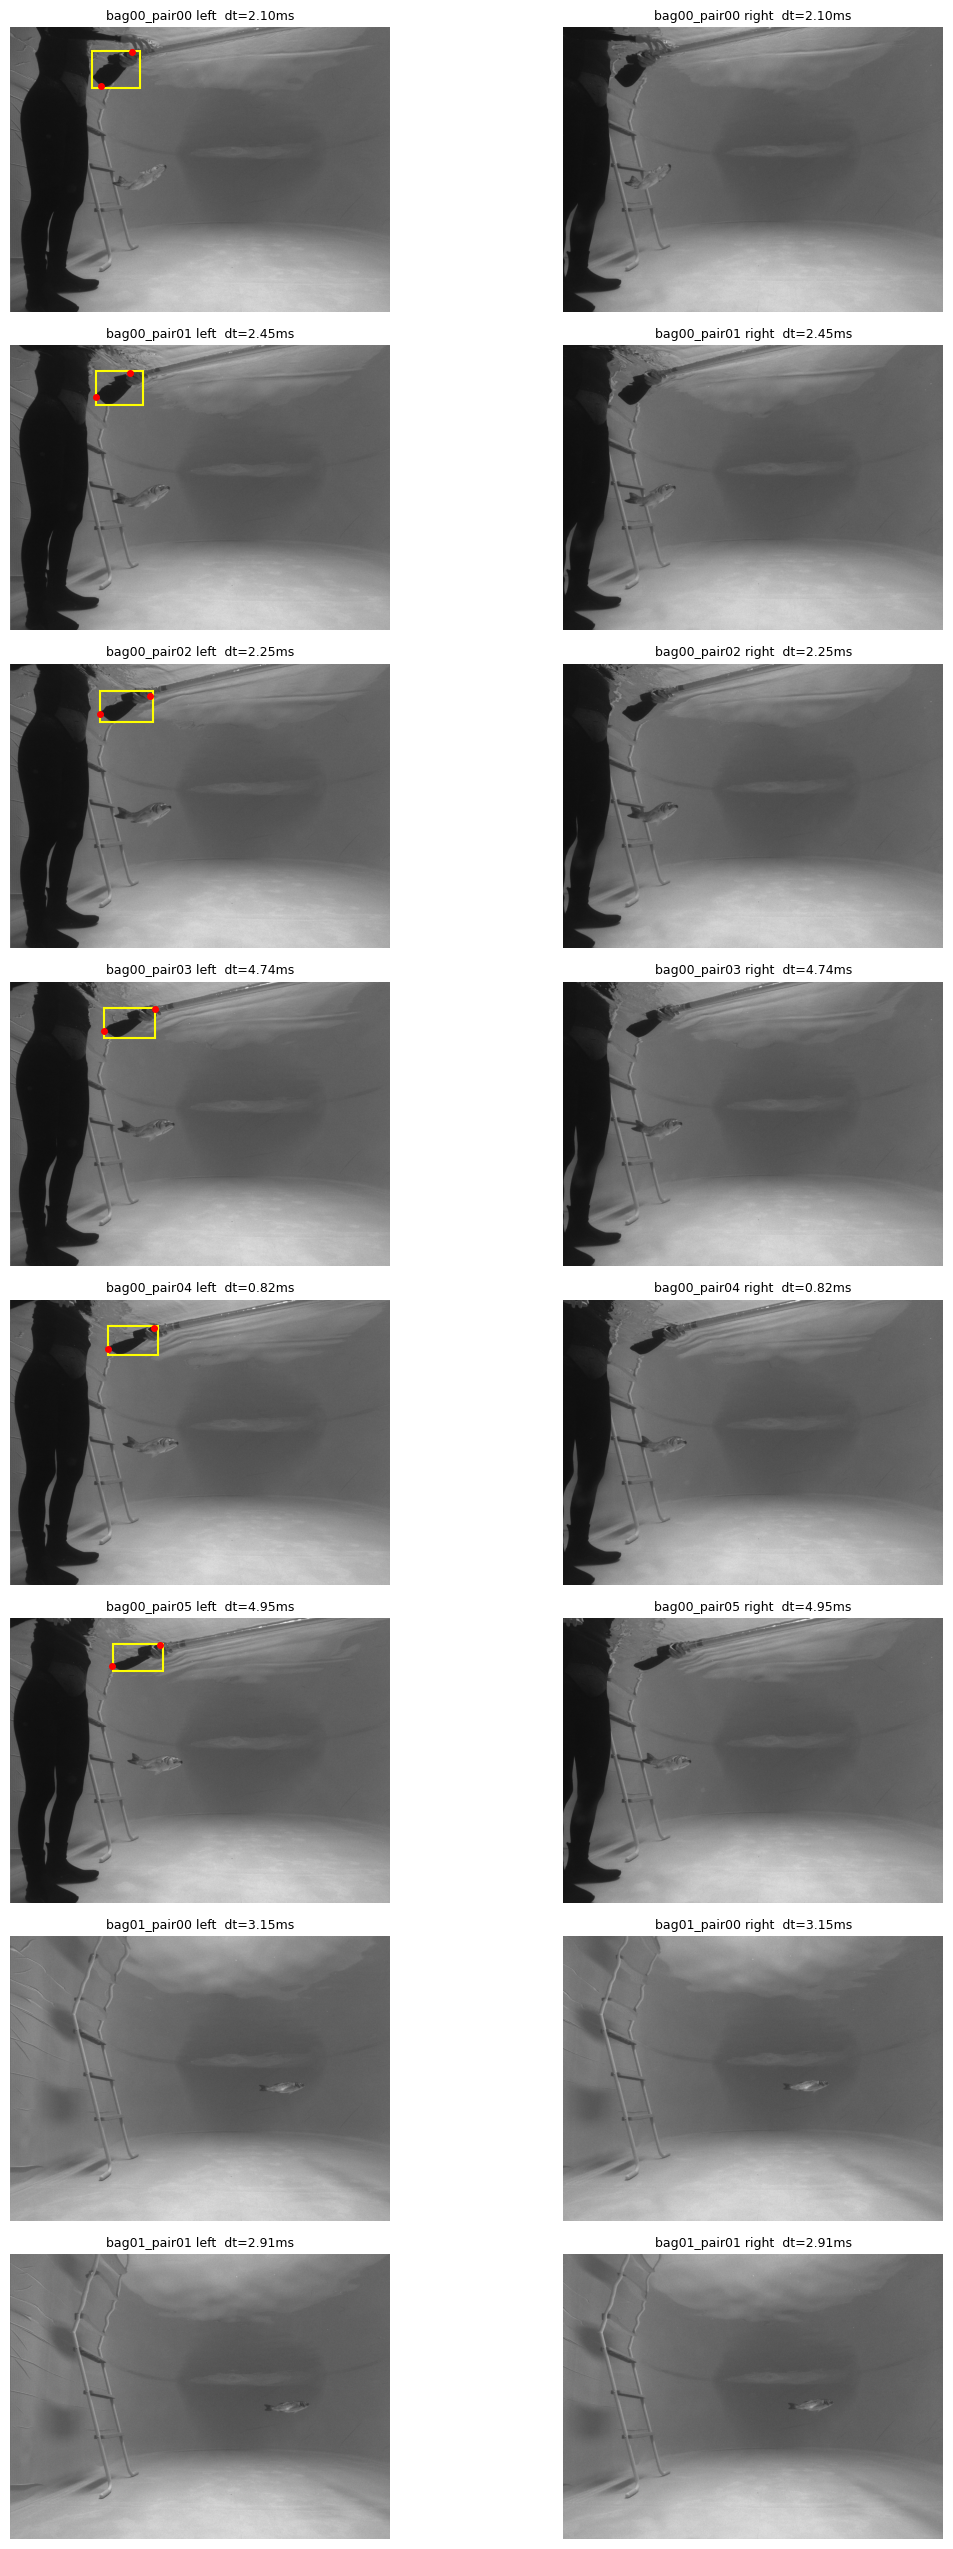

In [9]:
rows=min(8,len(pairs_df));fig,axes=plt.subplots(max(rows,1),2,figsize=(13,max(3,rows*3.2)),squeeze=False)
for i in range(rows):
    r=pairs_df.iloc[i]
    for k,side in enumerate(('left','right')):
        im=cv2.imread(str(pair_dir/r[side+'_image']))
        if im is None:continue
        im=cv2.cvtColor(im,cv2.COLOR_BGR2RGB)
        ax=axes[i,k];ax.imshow(im);ax.axis('off');ax.set_title(f'{r["pair_id"]} {side}  dt={r["delta_ms"]:.2f}ms',fontsize=9)
        picks=proposal_df[(proposal_df.pair_id==r['pair_id'])&(proposal_df.side==side)&(proposal_df['rank']==0)]
        if len(picks):
            from matplotlib.patches import Rectangle
            box=json.loads(picks.iloc[0].bbox_xywh)
            ax.add_patch(Rectangle((box[0],box[1]),box[2],box[3],fill=False,edgecolor='yellow',linewidth=1.5))
            for key in ('axis_end_a','axis_end_b'):
                val=picks.iloc[0][key]
                if isinstance(val,str):
                    px,py=json.loads(val);ax.plot(px,py,'ro',markersize=4)
for i in range(rows,len(axes)):
    for a in axes[i]:a.axis('off')
plt.tight_layout();plt.savefig(OUT/'stereo_review_sheet.png',dpi=120);plt.show()

## 9 — Strict 3D metric reconstruction: only independently verified keypoints
No shortcut from contrast blobs to fish length. For rectified images, 3D triangulation uses projection matrices whose scale must be known in metres, with horizontal disparity, epipolar tolerance, and positive depth checks. The head/tail landmarks must correspond to the same fish in both views.

In [10]:
ANNOT_COLS=['pair_id','bag','fish_id','dataset','left_nose_x','left_nose_y','right_nose_x','right_nose_y',
'left_tail_x','left_tail_y','right_tail_x','right_tail_y','calibration_session','baseline_m_verified',
'rectified_verified','identity_verified','endpoint_verified','ground_truth_cm','verification_reference']
template=OUT/'VERIFIED_fish_endpoints_TEMPLATE.csv'
pd.DataFrame(columns=ANNOT_COLS).to_csv(template,index=False)
map_cols=['bag','calibration_session','baseline_m_verified','rectified_verified','verification_reference']
pd.DataFrame(columns=map_cols).to_csv(OUT/'VERIFIED_calibration_map_TEMPLATE.csv',index=False)

def as_yes(v):return str(v).strip().lower() in ('1','true','yes','y')
def triangulate_rectified(p_l,p_r,K,baseline_m,epipolar_tol_px=2.0):
    xl,yl=map(float,p_l);xr,yr=map(float,p_r)
    fx,fy,cx,cy=K[0,0],K[1,1],K[0,2],K[1,2]
    disparity=xl-xr
    if not np.isfinite([xl,yl,xr,yr,fx,fy,baseline_m]).all():return None
    if fx<=0 or fy<=0 or baseline_m<=0 or disparity<=.5 or abs(yl-yr)>epipolar_tol_px:return None
    z=fx*baseline_m/disparity
    if z<=0 or not np.isfinite(z):return None
    return np.asarray(((xl-cx)*z/fx,(yl-cy)*z/fy,z),float)

measures=[]; failures=[]
if VERIFIED_ENDPOINTS.exists():
    verified=pd.read_csv(VERIFIED_ENDPOINTS)
    missing=set(ANNOT_COLS)-set(verified.columns)
    if missing:raise ValueError('Annotation CSV missing columns: '+str(sorted(missing)))
    for rec in verified.to_dict('records'):
        pair_id=str(rec['pair_id']);pair_match=pairs_df[pairs_df.pair_id==pair_id]
        if len(pair_match)!=1:failures.append({'pair_id':pair_id,'reason':'pair not found'});continue
        if not all(as_yes(rec[k]) for k in ('rectified_verified','identity_verified','endpoint_verified')) or not str(rec['verification_reference']).strip():
            failures.append({'pair_id':pair_id,'reason':'verification flags missing'});continue
        session=str(rec['calibration_session']);docs=cal_docs.get(session,{})
        if not ('left' in docs and 'right' in docs):failures.append({'pair_id':pair_id,'reason':'calibration session not found'});continue
        K=mat(docs['left'],'camera_matrix',(3,3))
        if K is None:failures.append({'pair_id':pair_id,'reason':'no left camera K'});continue
        # User must affirm baseline units, and source record must match actual calibration session.
        b=float(rec['baseline_m_verified'])
        if not np.isfinite(b) or b<=0:failures.append({'pair_id':pair_id,'reason':'baseline not verified'});continue
        gt_match=gt[(gt.Dataset.astype(str).str.lower().str.replace('dataset ','',regex=False)==str(rec['dataset']).lower().replace('dataset ','',1))&(gt.Identifier.astype(str)==str(rec['fish_id']))]
        if len(gt_match)!=1 or abs(float(gt_match.iloc[0].Total_Length_cm)-float(rec['ground_truth_cm']))>1e-6:
            failures.append({'pair_id':pair_id,'reason':'identity/length not found in GT'});continue
        points={}
        for landmark in ('nose','tail'):
            a=(rec[f'left_{landmark}_x'],rec[f'left_{landmark}_y'])
            q=(rec[f'right_{landmark}_x'],rec[f'right_{landmark}_y'])
            points[landmark]=triangulate_rectified(a,q,K,b)
        if any(x is None for x in points.values()):failures.append({'pair_id':pair_id,'reason':'triangulation rejected'});continue
        estimate=float(np.linalg.norm(points['nose']-points['tail'])*100)
        if not (0<estimate<1000):failures.append({'pair_id':pair_id,'reason':'length unreasonable'});continue
        measures.append({'pair_id':pair_id,'bag':rec['bag'],'fish_id':rec['fish_id'],'dataset':rec['dataset'],
                         'pred_cm':estimate,'ground_truth_cm':float(rec['ground_truth_cm']),
                         'absolute_error_cm':abs(estimate-float(rec['ground_truth_cm'])),'status':'ANNOTATED_GEOMETRY_CANDIDATE'})
else:print('[METRIC NOT RUN] Verified left/right fish endpoint annotations not supplied; no centimetre values invented.')
metric_df=pd.DataFrame(measures,columns=['pair_id','bag','fish_id','dataset','pred_cm','ground_truth_cm','absolute_error_cm','status'])
metric_df.to_csv(OUT/'verified_geometry_measurements_IF_AVAILABLE.csv',index=False)
pd.DataFrame(failures,columns=['pair_id','reason']).to_csv(OUT/'rejected_verified_annotations.csv',index=False)
display(metric_df)

[METRIC NOT RUN] Verified left/right fish endpoint annotations not supplied; no centimetre values invented.


,pair_id,bag,fish_id,dataset,pred_cm,ground_truth_cm,absolute_error_cm,status


## 10 — Evidence-controlled evaluation
In-sample annotated geometry error is not generalization. An independent fish-ID test must be predeclared. For the current recovered dataset, reliable held-out fish-size MAE may simply be unavailable.

In [11]:
metric_summary={'metric_validation_status':'NOT_EVALUATED','n_verified_geometry_rows':len(metric_df),
                'unique_fish_ids':int(metric_df[['dataset','fish_id']].drop_duplicates().shape[0]) if len(metric_df) else 0,
                'within_sample_geometry_mae_cm':None,'heldout_fish_mae_cm':None,'heldout_fish_rmse_cm':None}
if len(metric_df):
    metric_summary['within_sample_geometry_mae_cm']=float(metric_df.absolute_error_cm.mean())
    metric_summary['metric_validation_status']='VERIFIED_ANNOTATION_GEOMETRY_ONLY_NOT_HELDOUT'
if len(metric_df)==0:metric_summary['reason']='No accepted human-verified stereo landmark pairs and physical calibration'
(OUT/'metric_summary.json').write_text(json.dumps(metric_summary,indent=2,allow_nan=False),encoding='utf-8')
print(json.dumps(metric_summary,indent=2))

{
  "metric_validation_status": "NOT_EVALUATED",
  "n_verified_geometry_rows": 0,
  "unique_fish_ids": 0,
  "within_sample_geometry_mae_cm": null,
  "heldout_fish_mae_cm": null,
  "heldout_fish_rmse_cm": null,
  "reason": "No accepted human-verified stereo landmark pairs and physical calibration"
}


## 11 — Reproducible final report + portable outputs
Status reflects what actually ran, not the notebook title. It distinguishes original V8 training evidence from this notebook’s new geometry tests.

In [12]:
report={'project':'FishSizeEstimate','source_ros_bags_available':len(bags),
        'source_recovery':manifest.get('status','UNKNOWN'),
        'v8_pretraining':'COMPLETED_IN_PRIOR_KAGGLE_EXECUTION_NOT_RETRAINED_HERE',
        'actual_stereo_pairs_exported':len(pairs_df),
        'tracking_annotation_files_inspected':len(json_candidates),
        'tracking_nodes_with_recognized_keys':len(records_df),
        'automatic_mask_or_roi_proposals':len(proposal_df),
        'automatic_proposals_are_verified_fish':False,
        'verified_length_records':len(metric_df),
        'validated_heldout_length_mae_cm':None,
        'physical_scale_status':'VERIFIED_FROM_EXTERNAL_EVIDENCE_ONLY' if len(metric_df) else 'NOT_VERIFIED',
        'metric_summary':metric_summary,
        'data_limitations':['Recovered Dataset A comprises only Fish 0 recordings',
                            'Dataset B multiple fish require explicit per-frame identity',
                            'Source Dataset B archive incomplete',
                            'Tracking annotations might not encode nose/tail stereo point labels',
                            'Source projection translation units and image rectification need independent confirmation']}
(OUT/'FINAL_STATUS.json').write_text(json.dumps(report,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
readme="""# FishSizeEstimate — Final stereo measurement investigation\n\nThis output follows a successful V8 encoder pretraining. It does not retrain the encoder.\n\nThe notebook audits tracking annotations, exports real stereo pairs and object/endpoint review proposals, inspects calibration and performs guarded 3-D length reconstruction **only when independent verified annotations exist**.\n\nThe ROI/axis endpoints are **not automatically verified fish head/tail points**. Any projected baseline is not automatically in metres.\n\nReview `FINAL_STATUS.json` and `metric_summary.json` before any portfolio performance claims.\n"""
(OUT/'README.md').write_text(readme,encoding='utf-8')
archive=Path('/kaggle/working/FishSizeEstimate_Final_Research_Outputs.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    for p in OUT.rglob('*'):
        if p.is_file():z.write(p,p.relative_to(OUT.parent).as_posix())
print('ZIP:',archive,'bytes:',archive.stat().st_size)
print('FINAL STATUS:',report['physical_scale_status'],'\nLength measurements:',len(metric_df))

ZIP: /kaggle/working/FishSizeEstimate_Final_Research_Outputs.zip bytes: 754135511
FINAL STATUS: NOT_VERIFIED 
Length measurements: 0


## Interpretation and publication policy

**What has already succeeded:** V8 real ROS-frame self-supervised pretraining (10,405 image messages, 331 steps, 11/11 bags) and metadata/stereo QA based on the previous Kaggle run.

**What this final investigation can add:** evidence of the exact tracking annotation structure, reproducible full-resolution stereo pairs, conservative ROI candidate review, identified camera calibrations, optionally geometric measurements if externally verified annotations and baseline are available.

**What it cannot invent:** fish anatomical endpoints, identity-matched 3D landmarks, a metric baseline unit, or genuine independent-fish length accuracy. If these are absent, publishing *research prototype* is scientifically correct. Do not run untrusted downloaded pickle-based segmentation checkpoints without checking provenance and trusting the source. Dataset license must be verified before sharing imagery/checkpoints.